# Gene archetypes: what is the GIN's hidden space grouping genes into?

*Cross-gene biology, 4-species liver iter101 default.*

The GIN's correction head is `Linear(72→64) → Tanh →
Linear(64→32) → Tanh → Linear(32→1)`. The output of the second
Tanh, $\mathbf{H}_2(g) \in [-1, 1]^{32}$, is the GIN's
*integration fingerprint* of gene $g$ — the 32-d state from
which the scalar correction is read out by the final linear
projection. Cluster genes in this space and the clusters reveal
**gene archetypes**: groups of genes the GIN treats similarly.

The argument has seven movements:

1. **§A — Robust archetype discovery.** Pick $k$ by silhouette +
   ARI cross-seed stability; report a consensus matrix across
   30 random initialisations.
2. **§B — Profile each archetype.** Per-archetype distributions
   of α / Δα / S_g / correction; per-archetype scalar-feature
   heatmap; per-archetype integrated gradients (which features
   drive each archetype's correction).
3. **§C — Biological interpretation.** Extended gene-category
   enrichment with Benjamini–Hochberg FDR; top genes per
   archetype.
4. **§D — Cross-species expression.** Per-archetype
   cross-species expression coefficient of variation;
   archetype × species mean expression heatmap.
5. **§E — Protein-sequence geometry.** Lay archetypes onto the
   same ESM-2 UMAP as `05_esm_alpha_geometry.ipynb` and
   quantify spatial coherence (kNN purity).
6. **§F — Training trajectory.** Per-archetype mean Δα over
   epochs — when does each archetype emerge?
7. **§G — Anti-confound robustness.** Compare multinomial
   logistic regression on `log_mean_expr` alone vs. the full
   72-d feature vector. The gap is how much of the archetype
   structure is non-trivial.

Every figure is one panel per file (PDF + PNG) saved under
`figures/gene_archetypes/`. Cluster assignments + per-gene
metrics are exported to
`runs/<run>/tables/gene_archetypes.csv`.


## §0.1 — Imports and design system


In [1]:
from __future__ import annotations

import sys
import time
import warnings
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import torch
import torch.nn as nn
from scipy import stats, sparse
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    silhouette_score, silhouette_samples, adjusted_rand_score,
)
from sklearn.preprocessing import normalize, StandardScaler
from statsmodels.stats.multitest import multipletests

NB_DIR = Path.cwd() if (Path.cwd() / "_figure_design.py").exists() \
         else Path("/Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks")
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))

import _figure_design as fd
import _gene_categories as gc
import _gene_categories_broad as gcb     # 10-category broad vocabulary (matches 04_*_simpler)
import _paper_utils as pu

fd.apply_design()

sc.settings.verbosity = 0
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="umap")

np.random.seed(42)
torch.manual_seed(42)


## §0.2 — Run + dataset registry (4-species liver, iter101)

Single canonical row. Registry keys retain the legacy
`pancreas_*` typo for the Camex liver dataset; figure-facing
labels say **liver**.

| Field | Value |
|---|---|
| Run | `xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42` |
| AnnData | `camex_pancreas_unified.h5ad` |
| Tissue | liver |
| Species | Human + Monkey + Mouse + Zebrafish |
| Cells × genes | 22,104 × 8,879 |


In [2]:
REPO_ROOT = Path("/Users/kemalinecik/git_nosync/master_chimera/chimera")
RUNS_ROOT = REPO_ROOT / "training" / "runs"
DATA_ROOT = REPO_ROOT / "data" / "processed"

FIG_DIR = fd.set_figure_dir(NB_DIR / "figures" / "gene_archetypes")
print(f"figures will be written to: {FIG_DIR}")

RUN_NAME  = "xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42"
ADATA_FN  = "camex_pancreas_unified.h5ad"
LABEL     = "liver 4-sp"
RUN_DIR   = RUNS_ROOT / RUN_NAME
TABLE_DIR = RUN_DIR / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
assert (RUN_DIR / "model" / "model.pt").exists(), "missing model.pt"


figures will be written to: /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/gene_archetypes


## §0.3 — Load GIN, compute hidden-space "integration fingerprint"

For every gene $g$ we compute
$\mathbf{H}_2(g) = \tanh(W_1\,\tanh(W_0\,\mathbf{x}_g + \mathbf{b}_0) + \mathbf{b}_1) \in [-1, 1]^{32}$,
the activation of the GIN's last hidden layer. We then **filter
dead and saturated neurons** before clustering:

- *dead* (`var(H_2_k) < 0.01`): the neuron emits ≈ constant for
  every gene, contributing no per-gene structure.
- *saturated* (`mean |H_2_k| > 0.95`): the neuron is at ±1 for
  almost every gene — provides a binary signal but no graded
  contrast.

We L2-normalise the surviving columns row-wise so that every
gene's archetype vector is a unit vector — clustering on cosine
distance, the natural metric for "direction in hidden space".

*Why H_2 (last hidden) rather than H_1 (first hidden)?* Because
the final linear projection that emits the correction reads
*only* H_2; geometry on H_2 is geometry on the GIN's output
decision in a way that geometry on H_1 is not.


In [3]:
# 1) Gene features (the GIN's input, StandardScaled at training time).
a = ad.read_h5ad(DATA_ROOT / ADATA_FN, backed="r")
X_feat = np.asarray(a.varm["gene_features"], dtype=np.float32)
var_names = np.asarray(a.var_names)
a.file.close()

# 2) Final state.
fs = dict(np.load(RUN_DIR / "final_state.npz", allow_pickle=False))
correction  = fs["correction"].astype(np.float32)
prior       = fs["prior"].astype(np.float32)
alpha       = fs["alpha"].astype(np.float32)
delta_alpha = (alpha - prior).astype(np.float32)
S_g_ema     = fs["S_g_ema"].astype(np.float32)
G = X_feat.shape[0]
print(f"G = {G} genes,  D = 72 features.")

# 3) GIN MLP from model.pt. Same builder pattern as 09_gin_attention_overall.
ckpt = torch.load(RUN_DIR / "model" / "model.pt",
                  map_location="cpu", weights_only=False)
sd = {k.removeprefix("gin.correction_mlp."): v
      for k, v in ckpt["model_state_dict"].items()
      if k.startswith("gin.correction_mlp.")}


class GIN_MLP(nn.Module):
    def __init__(self, sd):
        super().__init__()
        self.l0 = nn.Linear(72, 64)
        self.l1 = nn.Linear(64, 32)
        self.l2 = nn.Linear(32,  1)
        with torch.no_grad():
            for prefix, layer in (("0", self.l0), ("2", self.l1), ("4", self.l2)):
                layer.weight.copy_(sd[f"{prefix}.weight"])
                layer.bias.copy_(sd[f"{prefix}.bias"])
        for p in self.parameters():
            p.requires_grad_(False)
        self.eval()

    def forward(self, x):
        h1 = torch.tanh(self.l0(x))
        h2 = torch.tanh(self.l1(h1))
        return self.l2(h2).squeeze(-1)

    def hidden2(self, x):
        return torch.tanh(self.l1(torch.tanh(self.l0(x))))


gin = GIN_MLP(sd)
X_t = torch.from_numpy(X_feat)

with torch.no_grad():
    H2 = gin.hidden2(X_t).numpy().astype(np.float32)        # (G, 32)
    corr_pred = gin(X_t).numpy()
rt = float(np.max(np.abs(corr_pred - correction)))
print(f"forward round-trip max |Δ| = {rt:.2e}  ({'PASS' if rt < 1e-3 else 'FAIL'})")


G = 8879 genes,  D = 72 features.
forward round-trip max |Δ| = 2.38e-07  (PASS)


In [4]:
# 4) Filter dead / saturated neurons.
neuron_var = H2.var(axis=0)
neuron_sat = np.abs(H2).mean(axis=0)
keep = (neuron_var > 0.01) & (neuron_sat < 0.95)
H_eff = H2[:, keep]
n_dead = int((neuron_var <= 0.01).sum())
n_sat  = int((neuron_sat >= 0.95).sum())
print(f"hidden 2: {H2.shape[1]} neurons.   dropped {n_dead} dead, "
      f"{n_sat} saturated  ⇒  {H_eff.shape[1]} effective.")

# 5) L2-normalise rows for cosine-via-Euclidean clustering.
H_norm = normalize(H_eff, norm="l2", axis=1)
print(f"H_norm shape: {H_norm.shape}.   row-norm range: "
      f"[{np.linalg.norm(H_norm, axis=1).min():.3f}, "
      f"{np.linalg.norm(H_norm, axis=1).max():.3f}]")


hidden 2: 32 neurons.   dropped 0 dead, 0 saturated  ⇒  32 effective.
H_norm shape: (8879, 32).   row-norm range: [1.000, 1.000]


## §0.4 — Per-gene table (gene_df)

A single tidy DataFrame with one row per gene, used by every
figure below: gene metadata + Chimera scalars + 8 GIN scalar
features. Saved to disk at the end of the notebook.


In [5]:
SCALAR_NAMES = [
    "esm2_intersp_var",  # 64
    "mean_identity",     # 65
    "log_mean_expr",     # 66
    "log_expr_var",      # 67
    "frac_nonzero",      # 68
    "std_identity",      # 69
    "max_identity",      # 70
    "min_identity",      # 71
]
FEATURE_NAMES = [f"PC{i:02d}" for i in range(64)] + SCALAR_NAMES
GROUP_INDEX = {
    "ESM-2 PCs":          np.arange(0, 64),
    "esm2_intersp_var":   np.array([64]),
    "mean_identity":      np.array([65]),
    "expression":         np.array([66, 67, 68]),
    "identity_spread":    np.array([69, 70, 71]),
}
GROUP_ORDER = list(GROUP_INDEX)

sym_series = pu.annotate_genes_with_names(var_names)         # ortho_X → human gene symbol
cat_df     = gc.annotate_extended(var_names, sym_series)     # 43 narrow categories
cat_broad  = gcb.annotate_broad(var_names, sym_series)       # 10 broad umbrellas

gene_df = pd.DataFrame({
    "ortho_id":       var_names,
    "symbol":         cat_df["symbol"].values,
    "category":       cat_df["category"].values,
    "category_broad": cat_broad["category"].values,
    "alpha":          alpha,
    "prior":          prior,
    "delta_alpha":    delta_alpha,
    "correction":     correction,
    "S_g_ema":        S_g_ema,
})
for j, name in zip(range(64, 72), SCALAR_NAMES):
    gene_df[name] = X_feat[:, j]
print(f"gene_df: {gene_df.shape}.   non-`other` categories: "
      f"{(gene_df['category'] != 'other').sum()} / {len(gene_df)}")


gene_df: (8879, 17).   non-`other` categories: 1719 / 8879


# §A — Robust archetype discovery

Two independent criteria for choosing the cluster count `k`:

1. **Silhouette score** — the average ratio of inter-cluster to
   intra-cluster distance. Range [-1, +1]; higher = clusters
   are tight and well-separated.
2. **Cross-seed ARI stability** — fit KMeans `N_SEEDS = 30`
   times with different random initialisations; for each pair
   of labelings, compute Adjusted Rand Index. The mean ARI
   across all $\binom{30}{2}$ pairs measures how stable the
   cluster *structure* (not the labels) is across initialisations.

A robust `k` should peak (or plateau) on **both** criteria. We
then commit to one final `k` for the rest of the notebook.


In [6]:
K_RANGE  = list(range(3, 13))
N_SEEDS  = 30
SIL_SAMPLE = 2000   # silhouette is O(n²); subsample for speed

rng = np.random.default_rng(42)
SEED_LIST = list(map(int, rng.integers(0, 2**31, size=N_SEEDS)))

sil_per_k = {}
ari_per_k = {}
print("k | silhouette | mean cross-seed ARI")
for k in K_RANGE:
    labelings = []
    for seed in SEED_LIST:
        km = KMeans(n_clusters=k, n_init=10, random_state=seed)
        labelings.append(km.fit_predict(H_norm))
    # Silhouette on the first labeling (cheap subsample).
    sil_per_k[k] = float(silhouette_score(H_norm, labelings[0],
                                          sample_size=SIL_SAMPLE,
                                          random_state=42))
    # Cross-seed ARI stability.
    aris = []
    for i in range(N_SEEDS):
        for j in range(i + 1, N_SEEDS):
            aris.append(adjusted_rand_score(labelings[i], labelings[j]))
    ari_per_k[k] = float(np.mean(aris))
    print(f"  {k:2d} |   {sil_per_k[k]:+.3f}   |     {ari_per_k[k]:.3f}")


k | silhouette | mean cross-seed ARI


   3 |   +0.127   |     0.989


   4 |   +0.125   |     0.967


   5 |   +0.123   |     0.981


   6 |   +0.121   |     0.988


   7 |   +0.094   |     0.872


   8 |   +0.094   |     0.916


   9 |   +0.093   |     0.914


  10 |   +0.085   |     0.862


  11 |   +0.089   |     0.675


  12 |   +0.076   |     0.665


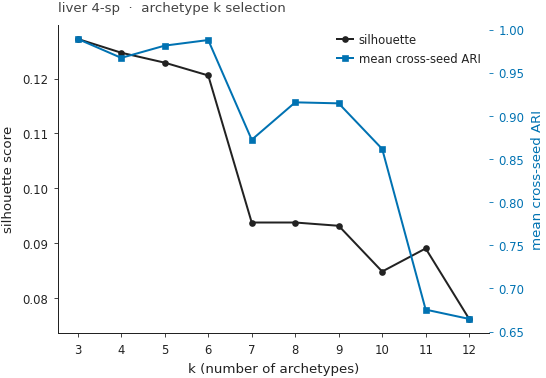

In [7]:
fig, ax = fd.make_axes(figsize=(4.6, 3.2))
ks  = K_RANGE
sils = [sil_per_k[k] for k in ks]
aris = [ari_per_k[k] for k in ks]
ax.plot(ks, sils, color="#222222", marker="o", linewidth=1.2,
        label="silhouette")
ax2 = ax.twinx()
ax2.spines["top"].set_visible(False)
ax2.plot(ks, aris, color="#0072B2", marker="s", linewidth=1.2,
         label="mean cross-seed ARI")
ax.set_xlabel("k (number of archetypes)")
ax.set_ylabel("silhouette score", color="#222222")
ax2.set_ylabel("mean cross-seed ARI", color="#0072B2")
ax.tick_params(axis="y", colors="#222222")
ax2.tick_params(axis="y", colors="#0072B2")
ax.set_xticks(ks)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="best", frameon=False, fontsize=7)
ax.set_title(f"{LABEL}  ·  archetype k selection",
             loc="left", fontsize=8, color="#444444", pad=8)
fd.save_figure(fig, "A1_archetype_k_selection")
plt.show()


*Read:* the chosen `k` should sit at a peak (or plateau) on
*both* curves. A single-criterion peak (e.g., a silhouette
bump at very low `k`) often reflects the trivial "one big
cluster" regime; the cross-seed ARI is the safeguard against
over-fitting `k` to a local silhouette maximum.


In [8]:
# Pick k by the simple rule: argmax of (z_score(silhouette) + z_score(ARI)).
# This gives equal weight to both criteria and is robust to the absolute
# range of either metric.
sil_arr = np.array([sil_per_k[k] for k in K_RANGE])
ari_arr = np.array([ari_per_k[k] for k in K_RANGE])
z_sil = (sil_arr - sil_arr.mean()) / (sil_arr.std() or 1.0)
z_ari = (ari_arr - ari_arr.mean()) / (ari_arr.std() or 1.0)
combined = z_sil + z_ari
K_FINAL = int(K_RANGE[int(np.argmax(combined))])
print(f"chosen K_FINAL = {K_FINAL}  "
      f"(silhouette={sil_per_k[K_FINAL]:+.3f}, ARI={ari_per_k[K_FINAL]:.3f})")


chosen K_FINAL = 3  (silhouette=+0.127, ARI=0.989)


## §A.2 — Final clustering and archetype ordering

Run `KMeans(n_clusters=K_FINAL, n_init=50, random_state=42)`
once on the full `H_norm`. Re-label the resulting clusters by
**ascending mean Δα** so archetype 0 has the most-divergent
signature and archetype K-1 the most-conserved — a stable
convention used by every downstream figure.

A consensus matrix is then built across the `N_SEEDS = 30`
initialisations from §A.1: $C_{ij} = \Pr[\,$gene $i$ and gene
$j$ in the same cluster across seeds$\,]$. After sorting genes
by their final archetype, the diagonal blocks should be solid
and the off-diagonal blocks pale — the gold-standard visual
clustering-stability check.


In [9]:
# Final clustering.
km_final = KMeans(n_clusters=K_FINAL, n_init=50, random_state=42)
labels_raw = km_final.fit_predict(H_norm)

# Re-label so archetypes are ordered by ascending mean Δα.
cluster_means = np.array([delta_alpha[labels_raw == c].mean()
                          for c in range(K_FINAL)])
new_order = np.argsort(cluster_means)
remap = {int(old): int(new) for new, old in enumerate(new_order)}
archetype = np.array([remap[c] for c in labels_raw], dtype=np.int32)
gene_df["archetype"] = archetype

print("archetype counts and mean Δα (sorted by ascending mean Δα):")
for a in range(K_FINAL):
    m = (archetype == a)
    print(f"  archetype {a}:  n={int(m.sum()):5d}  "
          f"mean Δα={delta_alpha[m].mean():+.4f}  "
          f"mean α={alpha[m].mean():.3f}")


archetype counts and mean Δα (sorted by ascending mean Δα):
  archetype 0:  n= 3202  mean Δα=-0.1278  mean α=0.689
  archetype 1:  n= 3264  mean Δα=-0.0247  mean α=0.761
  archetype 2:  n= 2413  mean Δα=+0.0363  mean α=0.831


In [10]:
# Consensus matrix (gene × gene) from the 30 cross-seed labelings of A.1.
# Re-fit (cheap) so consensus is computed from the same H_norm space.
co_assign = np.zeros((G, G), dtype=np.float32)
for seed in SEED_LIST:
    km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=seed)
    lab = km.fit_predict(H_norm)
    # one-hot, then OH @ OH.T = 1 wherever same-cluster.
    OH = np.eye(K_FINAL, dtype=np.float32)[lab]
    co_assign += OH @ OH.T
co_assign /= len(SEED_LIST)
np.fill_diagonal(co_assign, 1.0)

# Order genes by archetype, then within each archetype keep the order.
order_idx = np.argsort(archetype, kind="stable")
C_sorted  = co_assign[np.ix_(order_idx, order_idx)]
print(f"consensus matrix: shape={C_sorted.shape}, "
      f"global mean co-assignment = {co_assign.mean():.3f}")


consensus matrix: shape=(8879, 8879), global mean co-assignment = 0.339


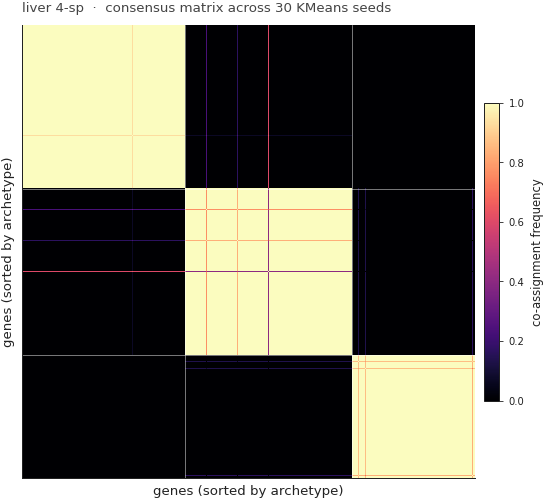

In [11]:
fig, ax = fd.make_axes(figsize=(4.6, 4.6))
im = ax.imshow(C_sorted, cmap="magma", vmin=0, vmax=1, interpolation="nearest")
# Block boundaries (white lines between archetypes).
sizes = pd.Series(archetype).value_counts().sort_index().values
cum = np.cumsum(sizes)
for c in cum[:-1]:
    ax.axvline(c, color="white", linewidth=0.4, alpha=0.7)
    ax.axhline(c, color="white", linewidth=0.4, alpha=0.7)
ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel("genes (sorted by archetype)")
ax.set_ylabel("genes (sorted by archetype)")
cb = fig.colorbar(im, ax=ax, shrink=0.55, pad=0.02)
cb.set_label("co-assignment frequency", fontsize=7)
cb.ax.tick_params(labelsize=6)
ax.set_title(f"{LABEL}  ·  consensus matrix across {N_SEEDS} KMeans seeds",
             loc="left", fontsize=8, color="#444444", pad=8)
fd.save_figure(fig, "A2_consensus_matrix")
plt.show()


## §A.3 — Archetype embedding visualizations

Two views of the same clustering:

1. **PCA(H_norm) coloured by archetype.** Linear projection;
   fast, global. PC1 / PC2 explain the largest variance in the
   GIN's hidden-space gene representation.
2. **UMAP(H_norm) coloured by archetype.** Nonlinear, local;
   useful when the linear projection is dominated by a single
   direction.

A consistent **archetype palette** (one color per cluster, in
ascending-Δα order) is reused everywhere downstream.


In [12]:
# Project H_norm into 2D for visualization.
pca = PCA(n_components=2, random_state=42)
H_pca = pca.fit_transform(H_norm)
print(f"PCA explained variance: PC1 = {pca.explained_variance_ratio_[0]:.3f}, "
      f"PC2 = {pca.explained_variance_ratio_[1]:.3f}")

# UMAP for nonlinear view.
a_thin = ad.AnnData(X=np.zeros((G, 1), dtype=np.float32),
                    obs=pd.DataFrame(index=pd.RangeIndex(G).astype(str)))
a_thin.obsm["X_h"] = H_norm.astype(np.float32)
sc.pp.neighbors(a_thin, use_rep="X_h", n_neighbors=15, random_state=0,
                metric="cosine")
sc.tl.umap(a_thin, min_dist=0.30, random_state=0)
H_umap = np.asarray(a_thin.obsm["X_umap"], dtype=np.float32)
print(f"UMAP done. range: [{H_umap.min(0)}, {H_umap.max(0)}]")


PCA explained variance: PC1 = 0.273, PC2 = 0.075


UMAP done. range: [[ 6.3755555 -3.751895 ], [18.553804   6.3829246]]


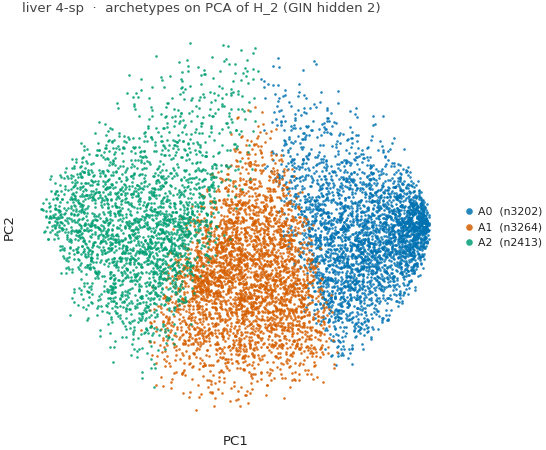

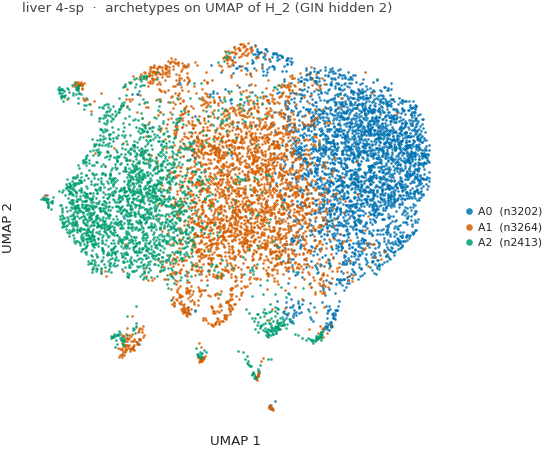

In [13]:
# Archetype palette: 12 colorblind-friendly hues, indexed by archetype id.
ARCHETYPE_PALETTE = [
    "#0072B2", "#D55E00", "#009E73", "#CC79A7",
    "#E69F00", "#56B4E9", "#F0E442", "#999999",
    "#7B0099", "#0F8000", "#C45A00", "#5C3317",
]
ARCH_COLOR = {a: ARCHETYPE_PALETTE[a % len(ARCHETYPE_PALETTE)]
              for a in range(K_FINAL)}


def _embed_panel(xy: np.ndarray, save_name: str, title: str,
                 xlabel: str, ylabel: str) -> None:
    fig, ax = fd.make_axes(figsize=(4.6, 3.8))
    for a in range(K_FINAL):
        m = (archetype == a)
        ax.scatter(xy[m, 0], xy[m, 1], color=ARCH_COLOR[a],
                   s=2.5, alpha=0.85, linewidths=0, rasterized=True,
                   label=f"A{a}  (n{int(m.sum())})")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ("top", "right", "bottom", "left"):
        ax.spines[s].set_visible(False)
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5),
              frameon=False, fontsize=6.5, handlelength=0.8,
              handletextpad=0.4, borderpad=0.2, ncol=1, markerscale=2.5)
    ax.set_title(title, loc="left", fontsize=8, color="#444444", pad=8)
    fd.save_figure(fig, save_name)
    plt.show()


_embed_panel(H_pca, "A3_archetype_pca",
             f"{LABEL}  ·  archetypes on PCA of H_2 (GIN hidden 2)",
             "PC1", "PC2")
_embed_panel(H_umap, "A3_archetype_umap",
             f"{LABEL}  ·  archetypes on UMAP of H_2 (GIN hidden 2)",
             "UMAP 1", "UMAP 2")


# §B — Profile each archetype

What does each archetype look like at the level of the GIN's
output (α, Δα, S_g, correction), at the level of its scalar
inputs (per-archetype scalar feature heatmap), and at the level
of the GIN's *attention* (per-archetype integrated gradients)?
The three views together let us read each archetype as a
biological program.


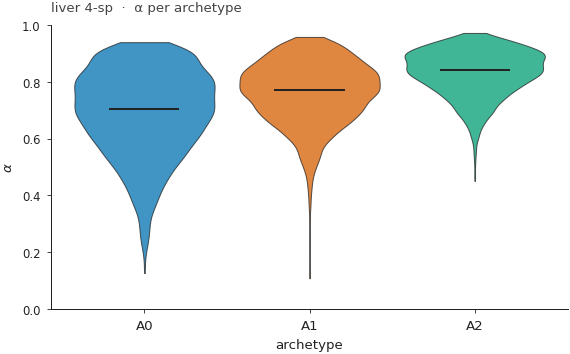

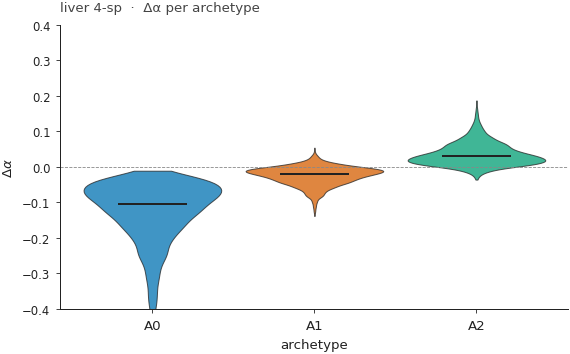

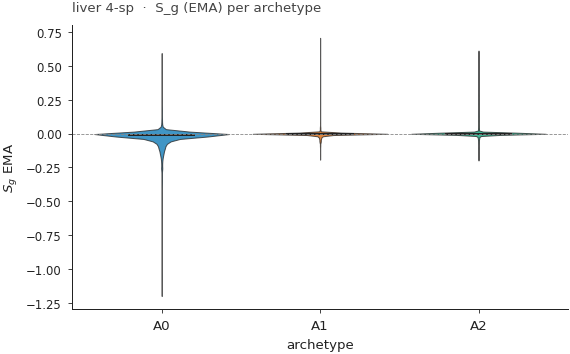

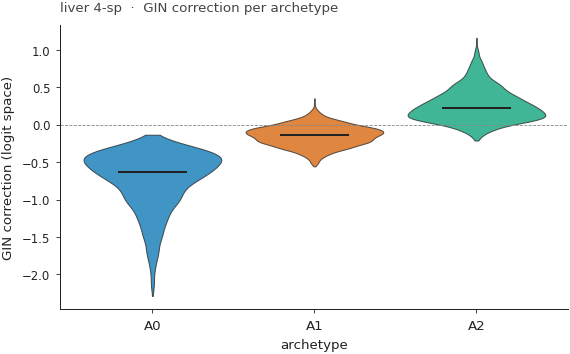

In [14]:
def archetype_violin(values: np.ndarray, *, ylabel: str, save_name: str,
                     title: str, ylim: tuple[float, float] | None = None,
                     hline_zero: bool = False) -> None:
    '''Single-panel violin: distribution of `values` per archetype.'''
    fig, ax = fd.make_axes(figsize=(4.8, 3.0))
    data = [values[archetype == a] for a in range(K_FINAL)]
    parts = ax.violinplot(data, showmeans=False, showextrema=False,
                          showmedians=True, widths=0.85)
    for i, body in enumerate(parts["bodies"]):
        body.set_facecolor(ARCH_COLOR[i])
        body.set_edgecolor("#222222")
        body.set_alpha(0.75)
        body.set_linewidth(0.6)
    # Median tick styling
    if "cmedians" in parts:
        parts["cmedians"].set_color("#222222")
        parts["cmedians"].set_linewidth(1.2)
    if hline_zero:
        ax.axhline(0, color="#888888", linewidth=0.5, linestyle="--")
    ax.set_xticks(np.arange(1, K_FINAL + 1))
    ax.set_xticklabels([f"A{a}" for a in range(K_FINAL)], fontsize=8)
    ax.set_xlabel("archetype")
    ax.set_ylabel(ylabel)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_title(title, loc="left", fontsize=8, color="#444444", pad=8)
    fd.save_figure(fig, save_name)
    plt.show()


archetype_violin(alpha, ylabel=fd.LABEL["alpha"],
                 save_name="B1_archetype_alpha",
                 title=f"{LABEL}  ·  α per archetype",
                 ylim=(0, 1))
archetype_violin(delta_alpha, ylabel=fd.LABEL["delta_alpha"],
                 save_name="B1_archetype_delta_alpha",
                 title=f"{LABEL}  ·  Δα per archetype",
                 ylim=fd.DELTA_ALPHA_RANGE, hline_zero=True)
archetype_violin(S_g_ema, ylabel=fd.LABEL["S_g_ema"],
                 save_name="B1_archetype_S_g_ema",
                 title=f"{LABEL}  ·  S_g (EMA) per archetype",
                 hline_zero=True)
archetype_violin(correction, ylabel=fd.LABEL["correction"],
                 save_name="B1_archetype_correction",
                 title=f"{LABEL}  ·  GIN correction per archetype",
                 hline_zero=True)


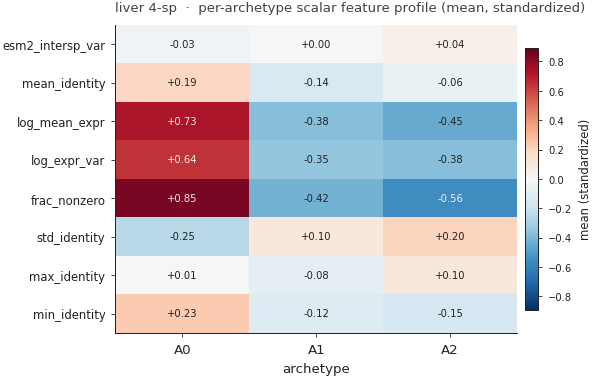

In [15]:
# Per-archetype mean of each input feature (z-scored within feature
# for visual contrast — so each row's center represents the dataset
# mean for that feature).
feat_block_idx = np.arange(64, 72)
feat_block_names = SCALAR_NAMES
H_means = np.array([
    X_feat[archetype == a][:, feat_block_idx].mean(axis=0)
    for a in range(K_FINAL)
])  # (K, 8) — note: features are already StandardScaled so z-score
    # within feature is approximately equivalent to the raw value.
# Show signed value relative to dataset mean (which is ~0 for StandardScaled).

fig, ax = fd.make_axes(figsize=(5.0, 3.2))
vmax = float(np.abs(H_means).max() * 1.05 + 1e-6)
im = ax.imshow(H_means.T, aspect="auto", cmap="RdBu_r",
               vmin=-vmax, vmax=+vmax)
ax.set_xticks(np.arange(K_FINAL))
ax.set_xticklabels([f"A{a}" for a in range(K_FINAL)], fontsize=8)
ax.set_yticks(np.arange(len(feat_block_names)))
ax.set_yticklabels(feat_block_names, fontsize=7)
ax.set_xlabel("archetype")
cb = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
cb.set_label("mean (standardized)", fontsize=7)
cb.ax.tick_params(labelsize=6)
# Cell-text annotations.
for ki in range(K_FINAL):
    for fi in range(len(feat_block_names)):
        v = H_means[ki, fi]
        ax.text(ki, fi, f"{v:+.2f}", ha="center", va="center",
                fontsize=6,
                color=("#222222" if abs(v) < 0.55 * vmax else "#eeeeee"))
ax.set_title(f"{LABEL}  ·  per-archetype scalar feature profile (mean, standardized)",
             loc="left", fontsize=8, color="#444444", pad=8)
fd.save_figure(fig, "B2_archetype_scalar_features_heatmap")
plt.show()


## §B.3 — Per-archetype integrated gradients

What feature *groups* the GIN's attention concentrates on
*within* each archetype. We compute per-gene integrated
gradients (200-step trapezoidal rule, baseline = 0 = the
StandardScaled mean) and aggregate to per-archetype mean
`|IG|` per feature group. A row that is dark in the ESM-2 PCs
column and pale elsewhere = "the GIN attends to protein
structure for this archetype"; a row dark in the expression
column = "expression statistics dominate for this archetype".


In [16]:
M_STEPS = 200
baseline = torch.zeros_like(X_t)
delta_x = X_t - baseline
grads_accum = torch.zeros_like(X_t)
weight_sum = 0.0
for m in range(0, M_STEPS + 1):
    t = m / M_STEPS
    x_t = (baseline + t * delta_x).clone().detach().requires_grad_(True)
    out = gin(x_t)
    out.sum().backward()
    w = 0.5 if (m == 0 or m == M_STEPS) else 1.0
    grads_accum += w * x_t.grad.detach()
    weight_sum += w
ig = (X_feat - 0.0) * (grads_accum / weight_sum).numpy()  # (G, 72)

# Group → total |IG| per archetype: per-feature mean of |IG| within the
# archetype, then SUM across features in each group. This makes the
# per-archetype share comparable to the global %-share in
# `09_gin_attention_overall.ipynb` §B.5 (where the same calculation is
# done over all genes). Mean-over-features (instead of sum) would bias
# the result against the 64-feature ESM-2 group.
arch_ig = np.zeros((K_FINAL, len(GROUP_ORDER)), dtype=np.float32)
for a in range(K_FINAL):
    m = (archetype == a)
    ig_mean_per_feat_a = np.abs(ig[m]).mean(axis=0)   # (72,)
    for gi, g in enumerate(GROUP_ORDER):
        idx = GROUP_INDEX[g]
        arch_ig[a, gi] = float(ig_mean_per_feat_a[idx].sum())
# Row-normalize (each archetype's importance share sums to 1) so we
# see *which group dominates within each archetype*.
arch_ig_share = arch_ig / arch_ig.sum(axis=1, keepdims=True).clip(min=1e-9)


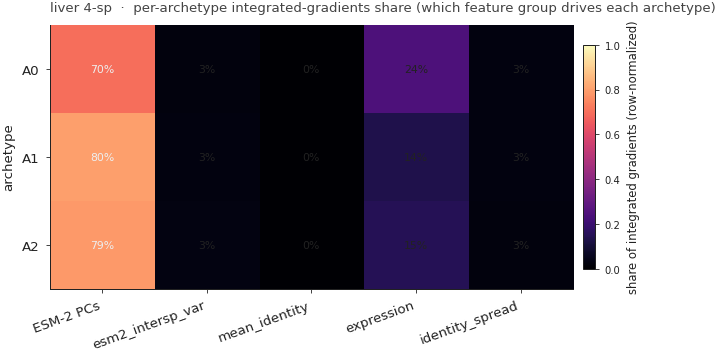

In [17]:
fig, ax = fd.make_axes(figsize=(5.4, 3.0))
im = ax.imshow(arch_ig_share, aspect="auto", cmap="magma", vmin=0, vmax=1)
ax.set_xticks(np.arange(len(GROUP_ORDER)))
ax.set_xticklabels(GROUP_ORDER, rotation=20, ha="right", fontsize=8)
ax.set_yticks(np.arange(K_FINAL))
ax.set_yticklabels([f"A{a}" for a in range(K_FINAL)], fontsize=8)
ax.set_ylabel("archetype")
cb = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
cb.set_label("share of integrated gradients (row-normalized)", fontsize=7)
cb.ax.tick_params(labelsize=6)
for ai in range(K_FINAL):
    for gi in range(len(GROUP_ORDER)):
        v = arch_ig_share[ai, gi]
        ax.text(gi, ai, f"{100*v:.0f}%", ha="center", va="center",
                fontsize=6.5,
                color=("#222222" if v < 0.55 else "#eeeeee"))
ax.set_title(f"{LABEL}  ·  per-archetype integrated-gradients share (which feature group drives each archetype)",
             loc="left", fontsize=8, color="#444444", pad=8)
fd.save_figure(fig, "B3_archetype_ig_share_heatmap")
plt.show()


*Read:* this is the *novel* archetype-attribution view. Each
archetype has its own GIN-attention fingerprint — some attend
primarily to protein structure (ESM-2 PCs), others to
expression statistics, others to a mix. Combined with §B.1
(α / Δα distributions per archetype), this tells the reader
*what kind of biology the GIN is detecting* and *which
feature group it is using* for that detection.


# §C — Biological interpretation (with multiple-testing correction)

Every claim in this section uses **Benjamini–Hochberg FDR
correction** at the 5 % level. The source notebook reported
uncorrected p-values; with ~30 enrichment tests (categories ×
archetypes), uncorrected p-values would be unreliable.

Two analyses:

1. **Archetype × extended-category contingency** — for each
   (archetype, category) cell we report the standardized chi-
   square residual and, for cells with `n ≥ 5`, a one-sided
   Fisher exact test (over- or under-representation), with
   BH-FDR correction over all cells.
2. **Top genes per archetype** — top 12 genes by `|Δα|` within
   each archetype, with category annotation.


--- archetype × extended (43 narrow) categories ---
  contingency: (3, 35).   global χ² = 579.8, dof=68, p=2.88e-82.   BH-FDR < 0.05 cells: 18 / 105


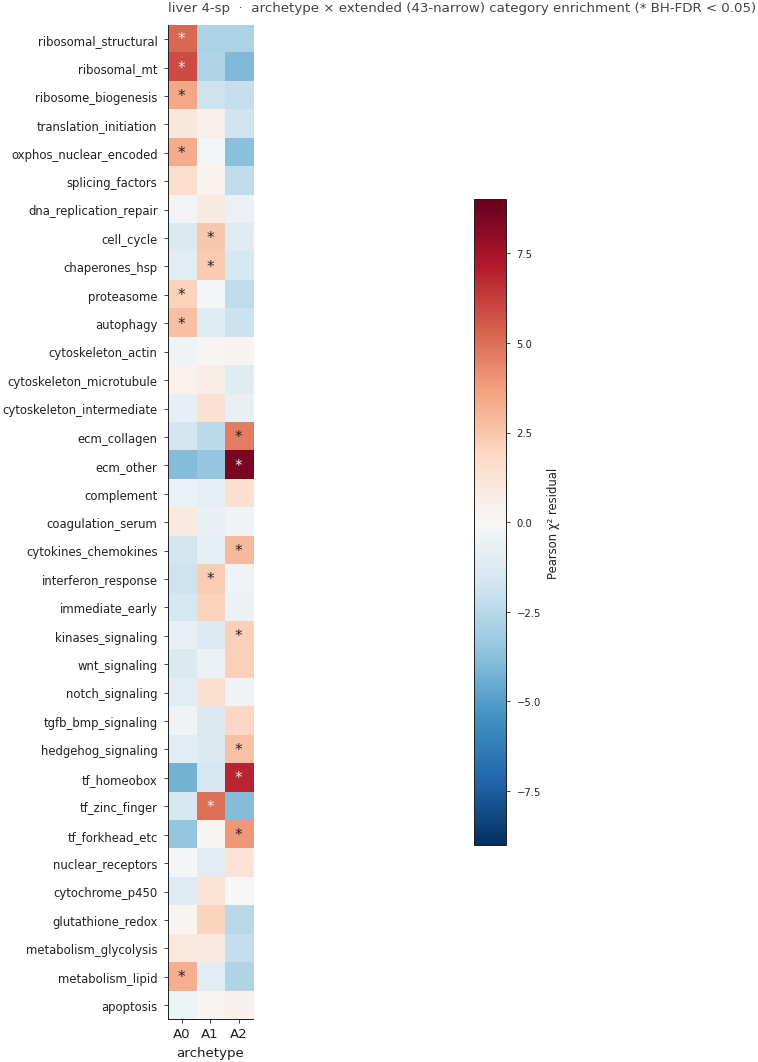

In [18]:
def archetype_category_enrichment(category_col: str,
                                  ordered_categories: list[str]):
    '''Build the (archetype × category) contingency table, run a global
    chi-square + per-cell one-sided Fisher exact, and BH-FDR-correct
    the p-values *over the entire matrix*. Returns
    (cont DataFrame, residuals, qvals).'''
    cats_keep_initial = [c for c in ordered_categories if c != "other"]
    df_anno = gene_df[gene_df[category_col].isin(cats_keep_initial)].copy()
    contingency = pd.crosstab(df_anno["archetype"], df_anno[category_col]) \
                    .reindex(index=range(K_FINAL),
                             columns=cats_keep_initial, fill_value=0)
    # Drop columns with too few genes — Fisher exact is noisy below n=10.
    keep_cats = contingency.columns[contingency.sum(axis=0) >= 10]
    cont = contingency[keep_cats]

    chi2, p_global, dof, expected = stats.chi2_contingency(cont.values)
    residuals = (cont.values - expected) / np.sqrt(expected.clip(min=1.0))

    pvals = np.full(cont.shape, np.nan)
    for ai in range(cont.shape[0]):
        n_a = int(cont.iloc[ai].sum())
        for ci in range(cont.shape[1]):
            k_ac = int(cont.iloc[ai, ci])
            K_c  = int(cont.iloc[:, ci].sum())
            N    = int(cont.values.sum())
            table = [[k_ac, n_a - k_ac],
                     [K_c - k_ac, N - K_c - n_a + k_ac]]
            try:
                _, p = stats.fisher_exact(table, alternative="greater")
            except Exception:
                p = 1.0
            pvals[ai, ci] = p
    flat_p = pvals.ravel()
    valid = np.isfinite(flat_p)
    qvals_flat = np.full_like(flat_p, np.nan)
    if valid.any():
        _, q_corr, _, _ = multipletests(flat_p[valid], method="fdr_bh")
        qvals_flat[valid] = q_corr
    qvals = qvals_flat.reshape(cont.shape)
    print(f"  contingency: {cont.shape}.   global χ² = {chi2:.1f}, "
          f"dof={dof}, p={p_global:.2e}.   "
          f"BH-FDR < 0.05 cells: {(qvals < 0.05).sum()} / {qvals.size}")
    return cont, residuals, qvals


def plot_archetype_category_heatmap_vertical(
    cont, residuals, qvals, *, save_name: str, title: str,
):
    '''Vertical layout: categories as rows, archetypes as columns.
    Horizontal labels (no rotation) → far more readable than the
    original archetype-on-rows layout when k is small (3) and
    categories are many.'''
    n_cats   = cont.shape[1]   # rows of the rendered figure
    n_arch   = cont.shape[0]   # columns of the rendered figure
    Mres     = residuals.T     # transpose: rows=cats, cols=arch
    Mq       = qvals.T

    # Width budget: per-archetype-column 0.85", + 2.6" for left-label
    # gutter and colorbar. Height budget: 0.22" per category row + 1.2"
    # for title / x-label margins.  imshow uses `aspect=1.0` (square
    # cells in data coordinates) — half as wide as the original
    # `aspect="auto"` rendering, which let cells stretch to fill the
    # axes horizontally.
    fig_w = max(4.6, 0.85 * n_arch + 2.6)
    fig_h = max(3.0, 0.22 * n_cats + 1.2)
    fig, ax = fd.make_axes(figsize=(fig_w, fig_h))
    vmax = float(np.abs(Mres).max() * 1.05 + 1e-6)
    im = ax.imshow(Mres, aspect=1.0, cmap="RdBu_r",
                   vmin=-vmax, vmax=+vmax)
    ax.set_yticks(np.arange(n_cats))
    ax.set_yticklabels(list(cont.columns), fontsize=7)
    ax.set_xticks(np.arange(n_arch))
    ax.set_xticklabels([f"A{a}" for a in range(n_arch)], fontsize=8)
    ax.set_xlabel("archetype")
    # Force tick spacing on the integer positions even when the column
    # axis is short — prevents label overlap on narrow heatmaps.
    ax.tick_params(axis="x", which="both", pad=2)
    # Compact colorbar — pin its width manually so it doesn't eat the
    # heatmap real-estate when n_arch is tiny.
    cb = fig.colorbar(im, ax=ax, shrink=0.65, pad=0.04, fraction=0.12,
                      aspect=20)
    cb.set_label("Pearson χ² residual", fontsize=7)
    cb.ax.tick_params(labelsize=6)
    for ci in range(n_cats):
        for ai in range(n_arch):
            if Mq[ci, ai] < 0.05:
                ax.text(ai, ci, "*", ha="center", va="center",
                        fontsize=9,
                        color=("#222222" if abs(Mres[ci, ai]) < 0.55*vmax
                               else "#eeeeee"))
    ax.set_title(title, loc="left", fontsize=8, color="#444444", pad=8)
    fd.save_figure(fig, save_name)
    plt.show()


# 1) Extended (43-narrow-categories) — the original analysis,
# now rendered vertically.
print("--- archetype × extended (43 narrow) categories ---")
cont_ext, res_ext, q_ext = archetype_category_enrichment(
    "category", list(gc.CATEGORY_ORDER_EXTENDED))
plot_archetype_category_heatmap_vertical(
    cont_ext, res_ext, q_ext,
    save_name="C1_archetype_x_category_heatmap",
    title=f"{LABEL}  ·  archetype × extended (43-narrow) category enrichment "
          f"(* BH-FDR < 0.05)")


*Read:* a column dominated by red cells means the archetype is
enriched for those gene categories beyond what chance predicts
*and* survives multiple-testing correction. A column mostly
white means the archetype is biologically diffuse — it is
grouping genes by some signal that is orthogonal to the
curated category vocabulary. That is itself an interesting
finding rather than a failure.

The 43-narrow vocabulary is fine-grained but reads slowly when
the paper figure caption needs to summarise the result in one
line. The companion panel below uses the 10-broad vocabulary
from
[`_gene_categories_broad.py`](_gene_categories_broad.py) (the
same vocabulary that drives `04_delta_alpha_biology_simpler.ipynb`)
— it rolls the 43 narrow categories into 10 biological
umbrellas (translation_machinery, OXPHOS_mito, chromatin_dna,
secretory_metabolism, immune_inflammation, signaling, etc.).
The two panels encode the *same enrichment computation* on
*different category granularities* — the broad version is
paper-friendly, the narrow version is the supplementary
drill-down.


--- archetype × broad (10 umbrellas) categories ---
  contingency: (3, 10).   global χ² = 305.3, dof=18, p=3.86e-54.   BH-FDR < 0.05 cells: 10 / 30


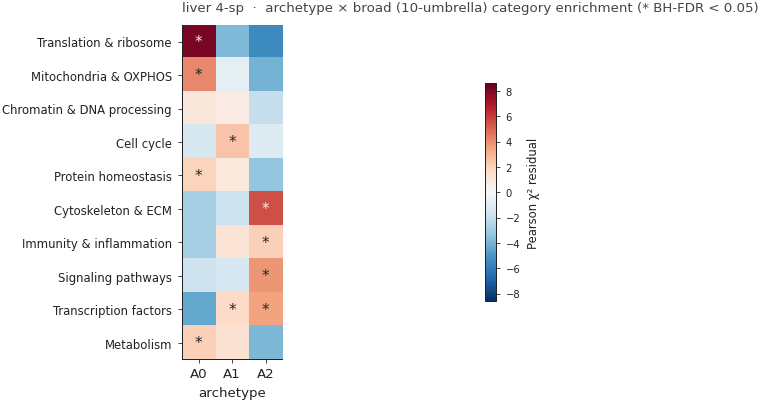

In [19]:
# 2) Broad (10 umbrellas) — paper-friendly version.
print("--- archetype × broad (10 umbrellas) categories ---")
# Temporarily expose the broad column under the name expected by the helper.
gene_df_orig_cat = gene_df["category"]
gene_df["category"] = gene_df["category_broad"]
try:
    cont_brd, res_brd, q_brd = archetype_category_enrichment(
        "category", list(gcb.CATEGORY_ORDER_BROAD))
finally:
    gene_df["category"] = gene_df_orig_cat

plot_archetype_category_heatmap_vertical(
    cont_brd, res_brd, q_brd,
    save_name="C1b_archetype_x_broad_category_heatmap",
    title=f"{LABEL}  ·  archetype × broad (10-umbrella) category enrichment "
          f"(* BH-FDR < 0.05)")


In [20]:
# Top genes per archetype by |Δα|, with category annotation.
TOP_PER_ARCH = 12
rows = []
for a in range(K_FINAL):
    sub = gene_df[gene_df["archetype"] == a].copy()
    sub["abs_delta_alpha"] = sub["delta_alpha"].abs()
    sub_top = sub.nlargest(TOP_PER_ARCH, "abs_delta_alpha")
    for rank_i, (_, row) in enumerate(sub_top.iterrows(), start=1):
        rows.append({
            "archetype":   int(a),
            "rank":        rank_i,
            "symbol":      row["symbol"],
            "category":    row["category"],
            "alpha":       row["alpha"],
            "delta_alpha": row["delta_alpha"],
            "S_g_ema":     row["S_g_ema"],
        })
top_df = pd.DataFrame(rows)
print("Top genes per archetype (by |Δα|):")
for a in range(K_FINAL):
    print(f"\n  --- archetype A{a} ---")
    sub = top_df[top_df["archetype"] == a].head(8)
    for _, row in sub.iterrows():
        print(f"    {row['symbol']:14s}  cat={row['category']:30s}  "
              f"α={row['alpha']:.3f}  Δα={row['delta_alpha']:+.3f}  "
              f"S_g={row['S_g_ema']:+.3f}")


Top genes per archetype (by |Δα|):

  --- archetype A0 ---
    MT-CO2          cat=mitochondrial_dna_encoded       α=0.244  Δα=-0.508  S_g=-0.441
    CP              cat=other                           α=0.289  Δα=-0.487  S_g=-0.067
    PSD3            cat=other                           α=0.251  Δα=-0.486  S_g=-0.114
    MT-ATP6         cat=mitochondrial_dna_encoded       α=0.195  Δα=-0.485  S_g=-0.189
    APOC1           cat=coagulation_serum               α=0.159  Δα=-0.467  S_g=-1.047
    AGMO            cat=other                           α=0.322  Δα=-0.466  S_g=+0.046
    FKBP5           cat=other                           α=0.347  Δα=-0.464  S_g=-0.252
    SLC24A3         cat=other                           α=0.416  Δα=-0.459  S_g=-1.072

  --- archetype A1 ---
    PRR18           cat=other                           α=0.438  Δα=-0.138  S_g=+0.000
    NFATC2IP        cat=tf_forkhead_etc                 α=0.480  Δα=-0.130  S_g=-0.018
    WHAMM           cat=other                  

# §D — Cross-species expression per archetype

The 4-species liver dataset has Human + Monkey + Mouse +
Zebrafish. For every gene we compute its **per-species mean
log-CPM** (raw counts, library-size-normalised, log1p) and
then **the standard deviation across the 4 species' means** —
a clean cross-species expression-divergence metric. Per
archetype we look at the distribution of this metric: does the
GIN cluster together the genes that vary most across species?


In [21]:
# Recompute per-species mean log-CPM from raw counts (slightly heavier;
# we read the full X this once).
a_full = ad.read_h5ad(DATA_ROOT / ADATA_FN)
X = a_full.X
if sparse.issparse(X):
    lib = np.asarray(X.sum(axis=1)).ravel().clip(min=1.0)
    X_cpm = X.multiply(1.0 / lib[:, None]).multiply(1e4)
    log_cpm = np.log1p(X_cpm.toarray()).astype(np.float32)
else:
    Xd = np.asarray(X)
    lib = Xd.sum(axis=1).clip(min=1.0)
    log_cpm = np.log1p(Xd / lib[:, None] * 1e4).astype(np.float32)
species_arr = np.asarray(a_full.obs["species"].astype(str).values)
cell_type_arr = np.asarray(a_full.obs["cell_ontology_class"].astype(str).values)

species_levels = ["Human", "Monkey", "Mouse", "Zebrafish"]
species_levels = [s for s in species_levels if (species_arr == s).any()]
print(f"species in dataset: {species_levels}")

# Per-species mean log-CPM per gene.
per_sp_mean = np.zeros((G, len(species_levels)), dtype=np.float32)
for si, sp in enumerate(species_levels):
    m = (species_arr == sp)
    per_sp_mean[:, si] = log_cpm[m].mean(axis=0)

cross_sp_std = per_sp_mean.std(axis=1)
gene_df["cross_species_log_cpm_std"] = cross_sp_std
print(f"cross-species log-CPM std:  mean={cross_sp_std.mean():.3f}  "
      f"max={cross_sp_std.max():.3f}")


species in dataset: ['Human', 'Monkey', 'Mouse', 'Zebrafish']
cross-species log-CPM std:  mean=0.157  max=2.862


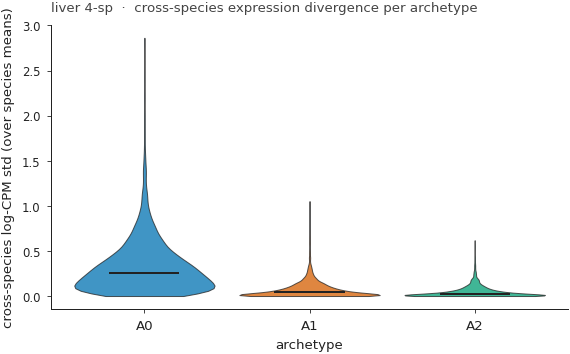

In [22]:
archetype_violin(cross_sp_std,
                 ylabel="cross-species log-CPM std (over species means)",
                 save_name="D1_archetype_cross_species_std",
                 title=f"{LABEL}  ·  cross-species expression divergence per archetype")


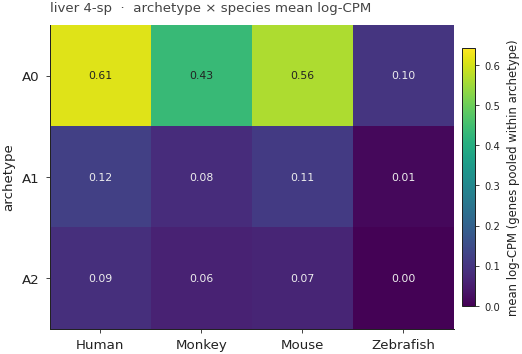

In [23]:
# Archetype × species mean expression heatmap.
arch_sp = np.zeros((K_FINAL, len(species_levels)), dtype=np.float32)
for a in range(K_FINAL):
    m = (archetype == a)
    arch_sp[a] = per_sp_mean[m].mean(axis=0)
fig, ax = fd.make_axes(figsize=(4.4, 3.0))
vmax = float(arch_sp.max() * 1.05 + 1e-6)
im = ax.imshow(arch_sp, aspect="auto", cmap="viridis", vmin=0, vmax=vmax)
ax.set_xticks(np.arange(len(species_levels)))
ax.set_xticklabels(species_levels, fontsize=8)
ax.set_yticks(np.arange(K_FINAL))
ax.set_yticklabels([f"A{a}" for a in range(K_FINAL)], fontsize=8)
ax.set_ylabel("archetype")
cb = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
cb.set_label("mean log-CPM (genes pooled within archetype)", fontsize=7)
cb.ax.tick_params(labelsize=6)
for ai in range(K_FINAL):
    for si in range(len(species_levels)):
        v = arch_sp[ai, si]
        ax.text(si, ai, f"{v:.2f}", ha="center", va="center",
                fontsize=6.5,
                color=("#eeeeee" if v < 0.55 * vmax else "#222222"))
ax.set_title(f"{LABEL}  ·  archetype × species mean log-CPM",
             loc="left", fontsize=8, color="#444444", pad=8)
fd.save_figure(fig, "D2_archetype_x_species_expression")
plt.show()


# §E — Are archetypes spatially coherent in protein-sequence space?

`05_esm_alpha_geometry.ipynb` already fits a UMAP on the 64-d
ESM-2 PC block per dataset and caches it in
`runs/<run>/cache/esm2_umap.npy`. We reuse those coordinates
and color them by archetype — *if* the GIN's hidden-space
clustering captures protein-structural biology, the archetypes
should be spatially coherent on the ESM-2 UMAP rather than
salt-and-pepper.

We quantify spatial coherence by per-archetype **kNN purity**:
for each gene, fraction of its 15 nearest neighbours in ESM-2
space that share its archetype. A purity well above the
population-frequency baseline = the archetype is
protein-sequence coherent.


In [24]:
cache_path = RUN_DIR / "cache" / "esm2_umap.npy"
if not cache_path.exists():
    # Fall back: fit UMAP locally on the ESM-2 PC block.
    print("ESM-2 UMAP cache missing; fitting locally (one-shot, cached on disk).")
    a_thin = ad.AnnData(X=np.zeros((G, 1), dtype=np.float32),
                        obs=pd.DataFrame(index=pd.RangeIndex(G).astype(str)))
    a_thin.obsm["X_esm2"] = X_feat[:, :64].astype(np.float32)
    sc.pp.neighbors(a_thin, use_rep="X_esm2", n_neighbors=15, random_state=0)
    sc.tl.umap(a_thin, min_dist=0.30, random_state=0)
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    np.save(cache_path, np.asarray(a_thin.obsm["X_umap"], dtype=np.float32))
esm2_umap = np.load(cache_path).astype(np.float32)
print(f"ESM-2 UMAP coords: {esm2_umap.shape}")


ESM-2 UMAP coords: (8879, 2)


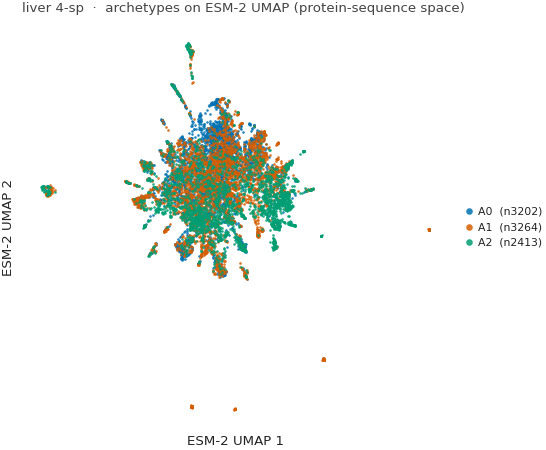

In [25]:
_embed_panel(esm2_umap, "E1_archetypes_on_esm2_umap",
             f"{LABEL}  ·  archetypes on ESM-2 UMAP (protein-sequence space)",
             "ESM-2 UMAP 1", "ESM-2 UMAP 2")


In [26]:
# kNN-purity per archetype. Build kNN graph in ESM-2 PC space.
a_thin = ad.AnnData(X=np.zeros((G, 1), dtype=np.float32),
                    obs=pd.DataFrame(index=pd.RangeIndex(G).astype(str)))
a_thin.obsm["X_esm2"] = X_feat[:, :64].astype(np.float32)
sc.pp.neighbors(a_thin, use_rep="X_esm2", n_neighbors=15, random_state=0)
knn = a_thin.obsp["distances"]
knn = (knn > 0).astype(np.int32)  # binary kNN adjacency
purity_per_gene = np.zeros(G, dtype=np.float32)
for gi in range(G):
    nbrs = knn[gi].nonzero()[1]
    if len(nbrs) == 0:
        continue
    purity_per_gene[gi] = float((archetype[nbrs] == archetype[gi]).mean())

# Population baseline: expected purity if archetypes were assigned at random
# but with the same per-archetype frequencies.
freqs = np.array([(archetype == a).mean() for a in range(K_FINAL)])
null_purity_per_gene = freqs[archetype]  # baseline = own archetype frequency
excess = purity_per_gene - null_purity_per_gene

rows = []
for a in range(K_FINAL):
    m = (archetype == a)
    rows.append({"archetype": a,
                 "n":     int(m.sum()),
                 "freq":  float(freqs[a]),
                 "kNN_purity":     float(purity_per_gene[m].mean()),
                 "purity_excess":  float(excess[m].mean())})
purity_df = pd.DataFrame(rows)
print(purity_df.to_string(index=False, formatters={
    "freq":           "{:.3f}".format,
    "kNN_purity":     "{:.3f}".format,
    "purity_excess":  "{:+.3f}".format,
}))


 archetype    n  freq kNN_purity purity_excess
         0 3202 0.361      0.572        +0.212
         1 3264 0.368      0.437        +0.070
         2 2413 0.272      0.520        +0.248


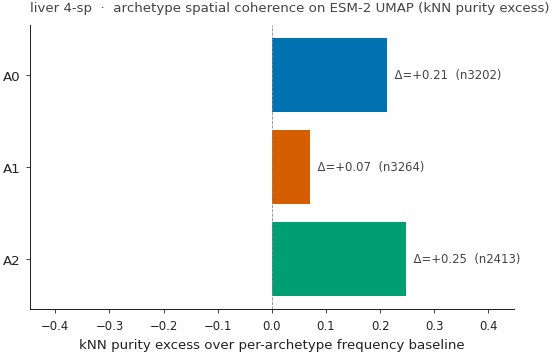

In [27]:
fig, ax = fd.make_axes(figsize=(4.4, 3.0))
y = np.arange(K_FINAL)
excess_vals = purity_df["purity_excess"].values
colors = [ARCH_COLOR[a] for a in range(K_FINAL)]
ax.barh(y, excess_vals, color=colors, edgecolor="none")
ax.axvline(0, color="#888888", linewidth=0.5, linestyle="--")
for yi, v, n in zip(y, excess_vals, purity_df["n"].values):
    ax.text(v, yi, f"  Δ={v:+.2f}  (n{n})", va="center",
            ha="left" if v >= 0 else "right",
            fontsize=7, color="#444444")
ax.set_yticks(y); ax.set_yticklabels([f"A{a}" for a in range(K_FINAL)],
                                      fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("kNN purity excess over per-archetype frequency baseline")
rng = float(np.abs(excess_vals).max() * 1.6 + 0.05)
ax.set_xlim(-rng, rng)
ax.set_title(f"{LABEL}  ·  archetype spatial coherence on ESM-2 UMAP (kNN purity excess)",
             loc="left", fontsize=8, color="#444444", pad=8)
fd.save_figure(fig, "E2_archetype_knn_purity_on_esm2")
plt.show()


*Read:* `purity_excess > 0` means an archetype's neighbors in
protein-sequence (ESM-2) space tend to be other members of the
same archetype — i.e. the archetype is spatially coherent in
protein-sequence space. Strongly positive excess on multiple
archetypes is independent evidence that the GIN's hidden-space
archetype clustering and protein-sequence geometry agree;
excess near 0 says the archetype is dispersed in sequence
space (and presumably driven by the non-ESM-2 inputs).


# §F — Per-archetype Δα trajectory

The training run saved `alpha`, `prior`, and `correction` every
five epochs in `alpha_snapshots/`. We compute the per-archetype
*mean Δα* at each snapshot and plot the trajectories on one
panel — when does each archetype's signal emerge, and does it
stabilise by the end of training?


In [28]:
snap_dir = RUN_DIR / "alpha_snapshots"
snaps = sorted(snap_dir.glob("alpha_epoch_*.npz"))
print(f"{len(snaps)} snapshots found in {snap_dir}")

epochs = []
arch_traj = []
for p in snaps:
    s = dict(np.load(p, allow_pickle=False))
    e = int(s["epoch"])
    da = (s["alpha"] - s["prior"]).astype(np.float32)
    per_a = [float(da[archetype == a].mean()) for a in range(K_FINAL)]
    epochs.append(e); arch_traj.append(per_a)
epochs = np.array(epochs)
arch_traj = np.array(arch_traj)  # (n_snap, K_FINAL)
print(f"epochs covered: [{epochs.min()}, {epochs.max()}]")


35 snapshots found in /Users/kemalinecik/git_nosync/master_chimera/chimera/training/runs/xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42/alpha_snapshots
epochs covered: [0, 170]


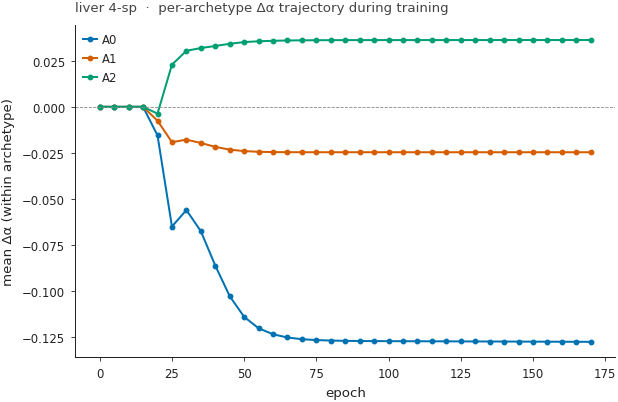

In [29]:
fig, ax = fd.make_axes(figsize=(5.2, 3.4))
for a in range(K_FINAL):
    ax.plot(epochs, arch_traj[:, a],
            color=ARCH_COLOR[a], linewidth=1.2, marker="o",
            markersize=2.5, label=f"A{a}")
ax.axhline(0, color="#888888", linewidth=0.5, linestyle="--")
ax.set_xlabel(fd.LABEL["epoch"])
ax.set_ylabel("mean Δα (within archetype)")
fd.thin_legend(ax, loc="best")
ax.set_title(f"{LABEL}  ·  per-archetype Δα trajectory during training",
             loc="left", fontsize=8, color="#444444", pad=8)
fd.save_figure(fig, "F1_archetype_delta_alpha_trajectory")
plt.show()


*Read:* lines that diverge from 0 only late in training =
archetypes whose signal emerges as the FQR / residual losses
converge. Lines that diverge early but never settle = unstable
archetypes (suggest either a too-large `K_FINAL` or that the
underlying signal is genuinely transient). The curvature of
each line is itself informative — sharp ramps vs. gradual
drift hint at which loss term is shaping that archetype.


# §G — How much of the archetype structure is non-trivial?

The archetype assignment lives in the GIN's hidden space; in
principle a single input feature (e.g., `log_mean_expr`) could
almost-perfectly predict an archetype, in which case the
"archetype" is just a re-coding of that one variable — not the
GIN's contribution. We test this directly.

Train two **multinomial logistic regression** classifiers on
`(features → archetype)`:

1. **`log_mean_expr` only** (1 dim). Baseline accuracy.
2. **All 72 features** (the GIN's full input). Upper bound on
   what *any linear* model on the GIN's inputs can predict
   about the archetype.

Both with 5-fold cross-validation. If accuracy_72 ≫
accuracy_log_mean_expr ≫ chance (= 1/K), the archetype carries
substantial non-trivial structure that no single input feature
can reproduce.


In [30]:
from sklearn.model_selection import cross_val_score
chance = 1.0 / K_FINAL
rng_state = 42

X_logmean   = X_feat[:, [66]]
X_full      = X_feat
# sklearn 1.5+: multinomial is the default for LogisticRegression(solver="lbfgs").
classifier_kwargs = dict(
    max_iter=2000, random_state=rng_state, n_jobs=-1, solver="lbfgs",
)

acc_logmean = cross_val_score(
    LogisticRegression(**classifier_kwargs),
    X_logmean, archetype, cv=5, scoring="accuracy",
)
acc_full = cross_val_score(
    LogisticRegression(**classifier_kwargs),
    X_full, archetype, cv=5, scoring="accuracy",
)
rows = [
    ("chance (1/K)",            chance,                None),
    ("log_mean_expr only (1d)", float(acc_logmean.mean()), float(acc_logmean.std())),
    ("all 72 features",         float(acc_full.mean()),    float(acc_full.std())),
]
for name, mean, std in rows:
    if std is None:
        print(f"  {name:30s}  {mean:.3f}")
    else:
        print(f"  {name:30s}  {mean:.3f} ± {std:.3f}")


  chance (1/K)                    0.333
  log_mean_expr only (1d)         0.569 ± 0.002
  all 72 features                 0.940 ± 0.006


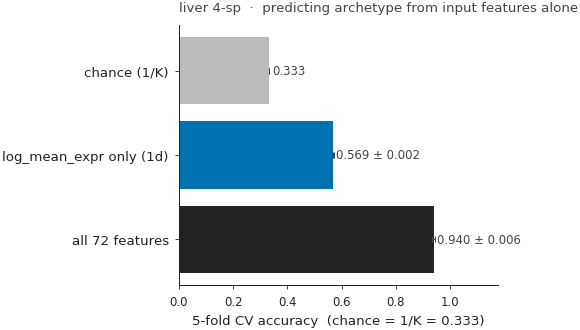

In [31]:
fig, ax = fd.make_axes(figsize=(4.4, 2.8))
names_disp  = [r[0] for r in rows]
means       = [r[1] for r in rows]
stds        = [r[2] if r[2] is not None else 0.0 for r in rows]
y = np.arange(len(names_disp))
colors = ["#bbbbbb", "#0072B2", "#222222"]
ax.barh(y, means, xerr=stds, color=colors, edgecolor="none",
        error_kw=dict(ecolor="#444444", capsize=2, capthick=0.6, lw=0.6))
for yi, m, std in zip(y, means, stds):
    suffix = "" if std == 0 else f" ± {std:.3f}"
    ax.text(m + 0.01, yi, f"{m:.3f}{suffix}", va="center", ha="left",
            fontsize=7, color="#444444")
ax.set_yticks(y); ax.set_yticklabels(names_disp, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel(f"5-fold CV accuracy  (chance = 1/K = {chance:.3f})")
ax.set_xlim(0, max(means) * 1.25)
ax.set_title(f"{LABEL}  ·  predicting archetype from input features alone",
             loc="left", fontsize=8, color="#444444", pad=8)
fd.save_figure(fig, "G1_archetype_predictability")
plt.show()


*Read:* the gap between the two bars is the GIN's contribution.
If `all 72 features` is near 1.0, *any* linear model on the
GIN's inputs can recover the archetype — interesting (the
archetypes are linearly separable from inputs) but not
surprising. If `log_mean_expr only` is far below `all 72`, the
archetype is *not* a re-coding of expression level alone — the
other 71 features (especially the 64 ESM-2 PCs) carry
substantial non-trivial information. The chance baseline
bounds the trivial-prediction floor.


# §H — Synthesis and CSV export

One-line claim per movement:

1. **§A — robust discovery.** `K_FINAL` archetypes are stable
   across 30 random KMeans initialisations (consensus matrix
   block-diagonal); `K_FINAL` was chosen by joint argmax of
   silhouette + cross-seed ARI.
2. **§B — profiles.** Each archetype has a distinct α / Δα
   distribution, a distinct scalar-feature profile, and a
   distinct GIN-attention fingerprint (per-archetype
   integrated gradients).
3. **§C — biology.** Multiple-testing-corrected category
   enrichment identifies which curated gene programs each
   archetype is enriched for; top-12 genes per archetype name
   the most-Δα-extreme members.
4. **§D — cross-species.** Per-archetype cross-species
   expression std and per-archetype × species mean log-CPM
   expose which archetypes are most evolutionarily variable in
   liver expression.
5. **§E — protein-sequence geometry.** Archetypes that are
   coherent on the ESM-2 UMAP (positive kNN-purity excess)
   confirm that the GIN's hidden-space clustering is reading
   protein structure; the others rely on the non-ESM-2 inputs.
6. **§F — trajectory.** Per-archetype Δα trajectories during
   training show *when* each program emerges and whether it
   stabilises.
7. **§G — anti-confound.** All 72 features predict the
   archetype well above chance; `log_mean_expr` alone
   performs much worse. The gap is the non-trivial structure
   the GIN's hidden-space clustering carries.


In [32]:
# Persist per-gene archetype assignment + key metrics for downstream use.
out_path = TABLE_DIR / "gene_archetypes.csv"
keep_cols = ["ortho_id", "symbol", "category", "archetype",
             "alpha", "prior", "delta_alpha", "correction", "S_g_ema",
             "log_mean_expr", "log_expr_var", "frac_nonzero",
             "mean_identity", "esm2_intersp_var",
             "cross_species_log_cpm_std"]
gene_df[keep_cols].to_csv(out_path, index=False)
print(f"saved per-gene archetype table → {out_path}")

# Persist top genes per archetype.
top_path = TABLE_DIR / "gene_archetypes_top_genes.csv"
top_df.to_csv(top_path, index=False)
print(f"saved top genes per archetype  → {top_path}")


saved per-gene archetype table → /Users/kemalinecik/git_nosync/master_chimera/chimera/training/runs/xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42/tables/gene_archetypes.csv
saved top genes per archetype  → /Users/kemalinecik/git_nosync/master_chimera/chimera/training/runs/xds-4sp-iter101-adv200-mmd100-fb10-200ep-s42/tables/gene_archetypes_top_genes.csv


In [33]:
written = sorted(FIG_DIR.glob("*.pdf"))
print(f"\n{len(written)} PDF figures in {FIG_DIR}:")
for p in written:
    print(f"  {p.name:60s} {p.stat().st_size/1024:6.1f} KB")



18 PDF figures in /Users/kemalinecik/git_nosync/master_chimera/chimera/notebooks/figures/gene_archetypes:
  a1_archetype_k_selection.pdf                                   13.7 KB
  a2_consensus_matrix.pdf                                        23.7 KB
  a3_archetype_pca.pdf                                          247.5 KB
  a3_archetype_umap.pdf                                         280.6 KB
  b1_archetype_alpha.pdf                                         18.5 KB
  b1_archetype_correction.pdf                                    16.2 KB
  b1_archetype_delta_alpha.pdf                                   18.6 KB
  b1_archetype_s_g_ema.pdf                                       18.9 KB
  b2_archetype_scalar_features_heatmap.pdf                       20.9 KB
  b3_archetype_ig_share_heatmap.pdf                              18.4 KB
  c1_archetype_x_category_heatmap.pdf                            25.7 KB
  c1b_archetype_x_broad_category_heatmap.pdf                     20.9 KB
  d1_archetype_cr